# 03 — Análise exploratória dos dados de treino

Vamos entender a distribuição das variáveis, os valores ausentes e os possíveis valores discrepantes antes de escolher o tratamento. As interpretações conectam as evidências às próximas decisões de modelagem.

**Entrada:** `data/processed/treino.csv`, gerado no notebook 02. **População analisada:** 25.932 registros de treino, após a remoção das repetições exatas. O conjunto de teste fica reservado para a avaliação final.

**Fonte:** [base de risco de crédito fornecida pelo professor](https://drive.google.com/file/d/1R4WCMc_56lv3fMaDalUBAz5jSxeZOcwI/view). O dicionário inicial e as limitações de definição estão no notebook 01.

Execute em ordem com o kernel da `.venv`. Este notebook produz quatro figuras em `docs/figuras/` e não altera os CSVs.


## 1. Ler somente o treino e verificar a versão

Conferimos o hash com `separacao.json` para garantir que a análise utiliza a divisão já definida. `numpy` auxilia os cálculos; `matplotlib` e `seaborn` produzem os gráficos. O logaritmo usado em uma visualização não altera as variáveis da tabela nem ajusta um pré-processador.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

relativo = Path("data/processed/treino.csv")
raiz = None
for pasta in (Path.cwd(), *Path.cwd().parents):
    if (pasta / relativo).is_file():
        raiz = pasta
        break
if raiz is None:
    raise FileNotFoundError("Execute primeiro o notebook 02 para gerar data/processed/treino.csv.")

caminho_treino = raiz / relativo
metadados = json.loads((raiz / "data/processed/separacao.json").read_text())
hash_treino = hashlib.sha256(caminho_treino.read_bytes()).hexdigest()
assert hash_treino == metadados["sha256_treino"], "O treino difere da divisão registrada."
treino = pd.read_csv(caminho_treino)
assert len(treino) == metadados["registros_treino"]
assert not treino.duplicated().any()

pasta_figuras = raiz / "docs/figuras"
pasta_figuras.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160})
print(f"Entrada: {relativo}")
print(f"Treino: {treino.shape[0]:,} registros e {treino.shape[1]} colunas.")


Entrada: data/processed/treino.csv
Treino: 25,932 registros e 12 colunas.


## 2. Dimensões, tipos e estatísticas descritivas

`info()` mostra os tipos e as contagens de valores preenchidos. `describe()` apresenta contagem, média, desvio padrão, mínimo, quartis e máximo. A mediana corresponde ao percentil 50%. Para categorias, mostramos quantidade de valores distintos e a categoria mais frequente.

O alvo é uma categoria binária armazenada como inteiro. Sua média equivale à proporção da classe 1, mas ele não é um atributo de entrada do modelo. Os valores financeiros têm moeda não informada e não serão rotulados como reais.


In [2]:
treino.info()
print("Estatísticas numéricas:")
display(treino.describe().round(2))
print("Resumo das categorias:")
display(treino.select_dtypes(exclude="number").describe())


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,25932.00,25932.00,25205.00,25932.00,23444.00,25932.00,25932.00,25932.00
mean,27.73,65828.51,4.77,9592.17,11.02,0.22,0.17,5.80
std,6.36,63093.01,4.15,6286.93,3.23,0.41,0.11,4.05
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38400.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,78643.75,7.00,12250.00,13.48,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,25932,25932,25932,25932
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,13114,5124,8584,21351


<class 'pandas.DataFrame'>
RangeIndex: 25932 entries, 0 to 25931
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  25932 non-null  int64  
 1   person_income               25932 non-null  int64  
 2   person_home_ownership       25932 non-null  str    
 3   person_emp_length           25205 non-null  float64
 4   loan_intent                 25932 non-null  str    
 5   loan_grade                  25932 non-null  str    
 6   loan_amnt                   25932 non-null  int64  
 7   loan_int_rate               23444 non-null  float64
 8   loan_status                 25932 non-null  int64  
 9   loan_percent_income         25932 non-null  float64
 10  cb_person_default_on_file   25932 non-null  str    
 11  cb_person_cred_hist_length  25932 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 2.4 MB
Estatísticas numéricas:
Resumo das categorias:

## 3. Gráfico 1 — Distribuição do alvo

Uma base desbalanceada tem mais registros de uma classe que da outra. Vamos mostrar tanto a contagem quanto a proporção, pois prever sempre a classe mais comum pode produzir uma acurácia aparentemente alta sem identificar inadimplência.


,registros,percentual
loan_status,,
0,20261,78.13
1,5671,21.87


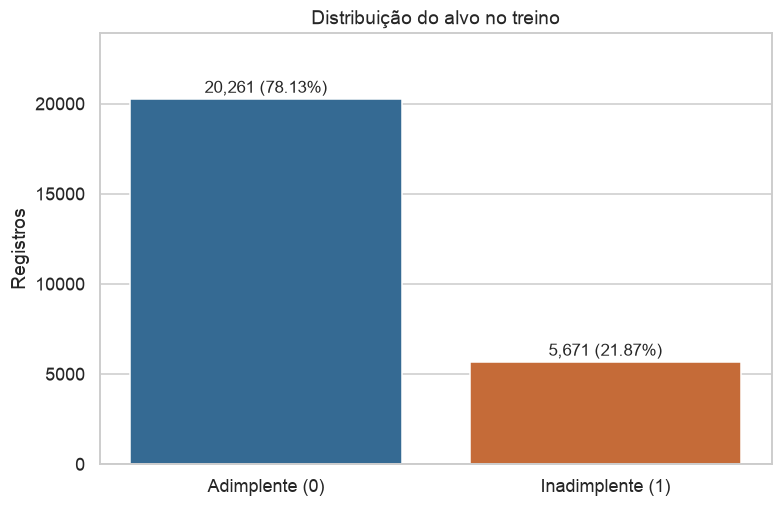

Acurácia de prever sempre a classe 0: 78.13%


In [3]:
contagens = treino["loan_status"].value_counts().reindex([0, 1], fill_value=0)
percentuais = contagens / len(treino) * 100
tabela_alvo = pd.DataFrame({"registros": contagens, "percentual": percentuais.round(2)})
display(tabela_alvo.rename_axis("loan_status"))

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
barras = ax.bar(["Adimplente (0)", "Inadimplente (1)"], contagens, color=["#356A93", "#C56B38"])
for barra, quantidade, percentual in zip(barras, contagens, percentuais):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 350,
            f"{quantidade:,} ({percentual:.2f}%)", ha="center", fontsize=11)
ax.set(title="Distribuição do alvo no treino", ylabel="Registros", ylim=(0, contagens.max() * 1.18))
ax.grid(axis="x", visible=False)
fig.savefig(pasta_figuras / "01_distribuicao_alvo.png")
display(fig)
plt.close(fig)
print(f"Acurácia de prever sempre a classe 0: {percentuais.loc[0]:.2f}%")


**Interpretação:** há 20.261 adimplentes (78,13%) e 5.671 inadimplentes (21,87%). Um classificador que sempre prevê adimplência teria 78,13% de acurácia e recall zero para inadimplentes. Por isso compararemos recall, F1 e ROC-AUC, matrizes de confusão e custos dos erros. O balanceamento deverá ser tratado dentro do treino, por exemplo com pesos de classe nos modelos que permitirem essa estratégia.


## 4. Diagnóstico de nulos e assimetria

Os percentuais de nulos usam todos os registros de treino como denominador. As estatísticas numéricas são calculadas sobre os valores observados. Assimetria positiva indica uma cauda à direita; a média pode ser puxada por valores altos. Não preencheremos os nulos durante a EDA.


In [4]:
resumo_nulos = pd.DataFrame({
    "nulos": treino.isna().sum(),
    "percentual": (treino.isna().mean() * 100).round(2),
})
display(resumo_nulos)
numericas = treino.select_dtypes(include="number").drop(columns="loan_status")
resumo_forma = pd.DataFrame({
    "media": numericas.mean(),
    "mediana": numericas.median(),
    "assimetria": numericas.skew(),
}).round(2)
display(resumo_forma)


,nulos,percentual
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,727,2.80
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,2488,9.59
loan_status,0,0.00
loan_percent_income,0,0.00


,media,mediana,assimetria
person_age,27.73,26.00,2.73
person_income,65828.51,55000.00,37.14
person_emp_length,4.77,4.00,2.94
loan_amnt,9592.17,8000.00,1.18
loan_int_rate,11.02,10.99,0.20
loan_percent_income,0.17,0.15,1.06
cb_person_cred_hist_length,5.80,4.00,1.66


**Interpretação e orientação de limpeza:** o tempo de emprego tem 727 nulos (2,80%), média 4,77 e mediana 4 anos, com assimetria positiva de 2,94. Isso favorece a mediana como candidata à imputação, após tratar os valores impossíveis. A taxa de juros tem 2.488 nulos (9,59%), média 11,02 e mediana 10,99, com assimetria pequena (0,20); a média é uma candidata defensável nessa coluna. São estratégias a implementar no pipeline, ajustadas apenas no treino de cada partição de validação. A EDA não demonstra por que os valores estão ausentes nem que a ausência seja aleatória.


## 5. Gráfico 2 — Distribuições numéricas

Os histogramas mostram a frequência por faixa. Mantemos todas as observações disponíveis, sem cortar valores extremos. Na renda usamos `log1p(renda)`, isto é, o logaritmo natural de `1 + renda`, apenas para tornar legível a distribuição muito assimétrica. Os demais painéis usam os valores originais. Nulos são excluídos apenas do respectivo gráfico.


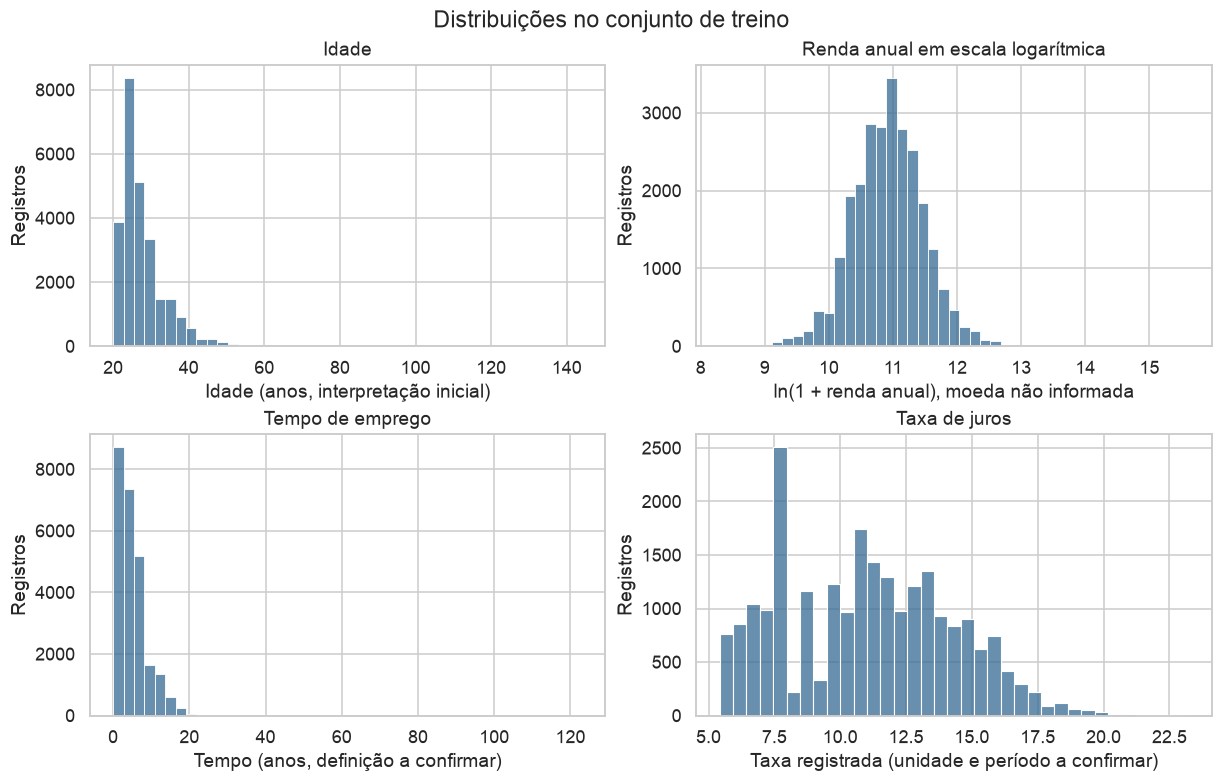

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
sns.histplot(treino["person_age"].dropna(), bins=45, ax=axes[0, 0], color="#356A93")
axes[0, 0].set(title="Idade", xlabel="Idade (anos, interpretação inicial)", ylabel="Registros")
sns.histplot(np.log1p(treino["person_income"].dropna()), bins=45, ax=axes[0, 1], color="#356A93")
axes[0, 1].set(title="Renda anual em escala logarítmica", xlabel="ln(1 + renda anual), moeda não informada", ylabel="Registros")
sns.histplot(treino["person_emp_length"].dropna(), bins=45, ax=axes[1, 0], color="#356A93")
axes[1, 0].set(title="Tempo de emprego", xlabel="Tempo (anos, definição a confirmar)", ylabel="Registros")
sns.histplot(treino["loan_int_rate"].dropna(), bins=35, ax=axes[1, 1], color="#356A93")
axes[1, 1].set(title="Taxa de juros", xlabel="Taxa registrada (unidade e período a confirmar)", ylabel="Registros")
fig.suptitle("Distribuições no conjunto de treino", fontsize=15)
fig.savefig(pasta_figuras / "02_distribuicoes_numericas.png")
display(fig)
plt.close(fig)


**Interpretação:** a renda tem média de 65.828,51 e mediana de 55.000, com máximo de 6.000.000 e assimetria de 37,14. Há uma cauda longa que exige cuidado com escala e valores extremos; o valor alto, isoladamente, não prova erro. Idade máxima de 144 e tempo de emprego máximo de 123 anos apontam casos a investigar com regras de plausibilidade. O uso do log no gráfico não implica aplicar essa transformação no modelo.


## 6. Outliers: evidência estatística e coerência dos registros

O intervalo interquartil (IQR) é `Q3 - Q1`. Marcamos valores abaixo de `Q1 - 1,5 × IQR` ou acima de `Q3 + 1,5 × IQR`. Esses limites identificam observações incomuns, não erros automaticamente. Calculamos os limites por variável, sem incluir o alvo, e não removemos registros.

O exemplo da idade é importante: o limite superior estatístico é 40,5 anos, mas ter mais de 40,5 anos não torna um cliente inválido. Regras de plausibilidade são uma decisão diferente da regra IQR.


In [6]:
linhas_iqr = []
for coluna in numericas.columns:
    serie = treino[coluna].dropna()
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    fora = (serie < inferior) | (serie > superior)
    linhas_iqr.append({"coluna": coluna, "limite_inferior": inferior, "limite_superior": superior,
                       "fora_iqr": int(fora.sum()), "pct_observados": fora.mean() * 100})
tabela_iqr = pd.DataFrame(linhas_iqr).set_index("coluna")
display(tabela_iqr.round(2))

idade_suspeita = treino["person_age"] > 100
emprego_incompativel = treino["person_emp_length"] > treino["person_age"]
diagnostico_plausibilidade = pd.Series({
    "idade_acima_100_requer_revisao": int(idade_suspeita.sum()),
    "tempo_emprego_maior_que_idade": int(emprego_incompativel.sum()),
    "renda_nao_positiva": int((treino["person_income"] <= 0).sum()),
}, name="registros")
display(diagnostico_plausibilidade.to_frame())
display(treino.loc[idade_suspeita | emprego_incompativel,
                   ["person_age", "person_emp_length", "person_income"]])


,limite_inferior,limite_superior,fora_iqr,pct_observados
coluna,,,,
person_age,12.50,40.50,1187,4.58
person_income,-21965.62,139009.38,1278,4.93
person_emp_length,-5.50,14.50,669,2.65
loan_amnt,-5875.00,23125.00,1307,5.04
loan_int_rate,-0.47,21.85,3,0.01
loan_percent_income,-0.12,0.44,522,2.01
cb_person_cred_hist_length,-4.50,15.50,906,3.49


,registros
idade_acima_100_requer_revisao,5
tempo_emprego_maior_que_idade,2
renda_nao_positiva,0


,person_age,person_emp_length,person_income
1951,123,7.0,78000
7634,22,123.0,59000
8519,21,123.0,192000
20234,144,4.0,200000
20958,144,4.0,250000
21717,144,12.0,6000000
23554,123,2.0,80004


## 7. Gráfico 3 — Boxplots com valores extremos

Cada painel tem sua própria escala. A caixa resume o centro da distribuição e os pontos mostram observações além dos limites do boxplot. Todos os valores observados são mantidos.


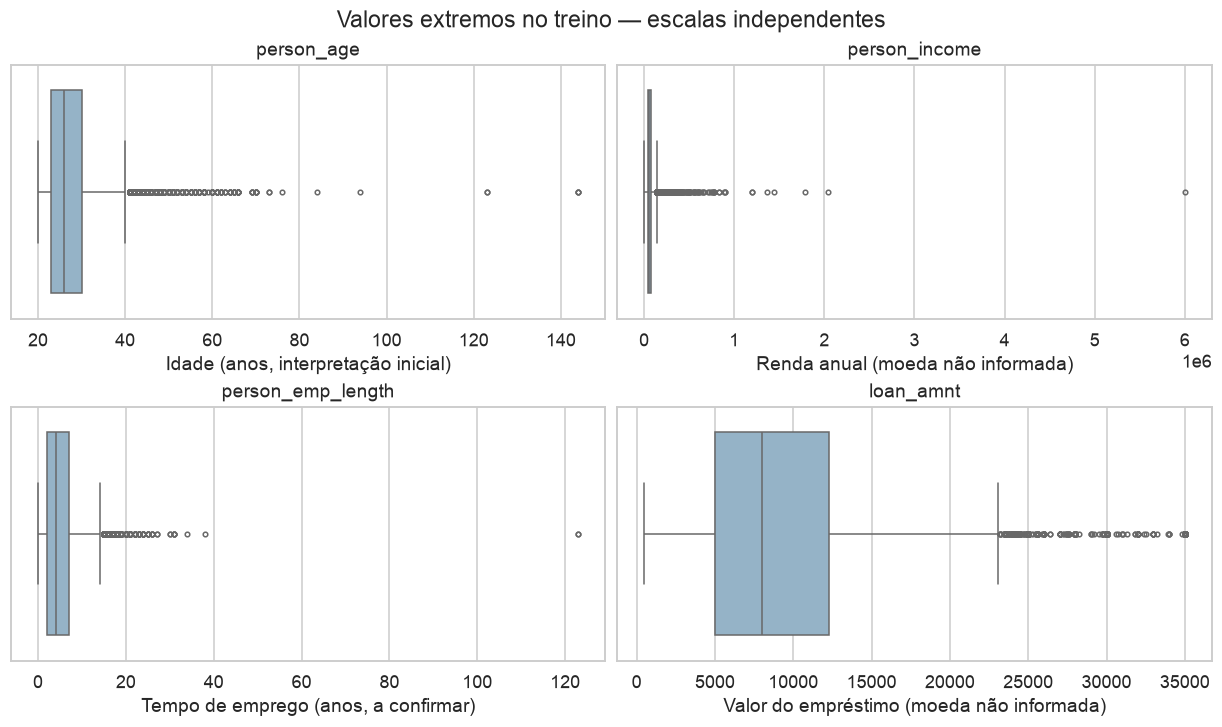

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), layout="constrained")
campos = ["person_age", "person_income", "person_emp_length", "loan_amnt"]
rotulos = ["Idade (anos, interpretação inicial)", "Renda anual (moeda não informada)",
           "Tempo de emprego (anos, a confirmar)", "Valor do empréstimo (moeda não informada)"]
for ax, coluna, rotulo in zip(axes.flat, campos, rotulos):
    sns.boxplot(x=treino[coluna].dropna(), ax=ax, color="#8DB4CF", fliersize=3)
    ax.set(xlabel=rotulo, title=coluna)
fig.suptitle("Valores extremos no treino — escalas independentes", fontsize=15)
fig.savefig(pasta_figuras / "03_boxplots.png")
display(fig)
plt.close(fig)


**Orientação de tratamento:** há cinco idades acima de 100 anos e dois registros com tempo de emprego maior que a idade. O limite de 100 é um sinal de revisão adotado no projeto, não um limite universal. Na próxima etapa definiremos regras explícitas para esses campos, evitando inferir valores corretos sem evidência. Valores financeiros raros, mas plausíveis, serão inicialmente mantidos; remoção ou clipping indiscriminados poderiam descartar clientes relevantes.

Modelos baseados em distância e a Regressão Logística são sensíveis à escala e podem sofrer influência de extremos. O `StandardScaler` será ajustado dentro do pipeline quando necessário, mas ele não torna os outliers inofensivos. Modelos baseados em árvores não exigem padronização e tendem a ser menos sensíveis à magnitude isolada; ainda assim podem aprender ruído. A comparação com validação ajudará a avaliar o efeito das decisões.


## 8. Gráfico 4 — Correlação das variáveis numéricas

Usamos correlação de Pearson, que mede associação linear entre -1 e 1. Valores ausentes são excluídos par a par. O alvo aparece para investigação, mas será excluído das entradas de treinamento. Categorias em texto não entram nesta matriz. Uma correlação baixa não descarta relações não lineares, e correlação não demonstra causalidade.


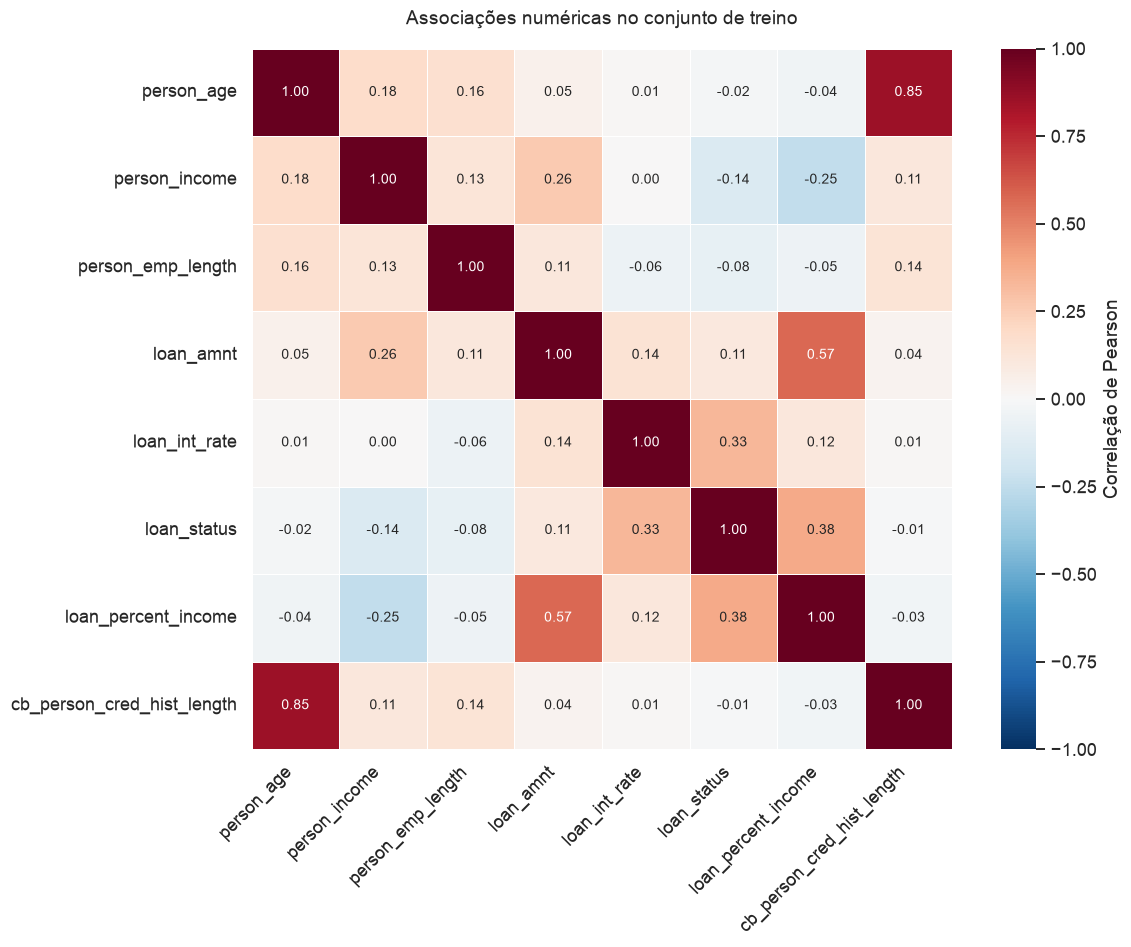

,correlacao_com_alvo
loan_percent_income,0.380
loan_int_rate,0.334
loan_amnt,0.108
cb_person_cred_hist_length,-0.015
person_age,-0.020
person_emp_length,-0.082
person_income,-0.141


In [8]:
correlacao = treino.select_dtypes(include="number").corr(method="pearson")
fig, ax = plt.subplots(figsize=(10.5, 8.5), layout="constrained")
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, annot_kws={"size": 9},
            cbar_kws={"label": "Correlação de Pearson"}, ax=ax)
ax.set_title("Associações numéricas no conjunto de treino", pad=16)
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
fig.savefig(pasta_figuras / "04_correlacao.png")
display(fig)
plt.close(fig)
display(correlacao["loan_status"].drop("loan_status").sort_values(ascending=False).round(3).to_frame("correlacao_com_alvo"))


**Interpretação:** entre os campos numéricos, a associação positiva com inadimplência é maior em `loan_percent_income` (0,380) e `loan_int_rate` (0,334). A renda tem associação negativa (-0,141). Essas observações ajudam a formular hipóteses, mas não bastam para escolher variáveis nem garantem desempenho preditivo. A disponibilidade temporal das informações de entrada também precisa ser considerada antes da API.


## 9. Relação entre a coluna existente e a nova variável obrigatória

O roteiro exige calcular `comprometimento_renda = (loan_amnt / person_income) × 100`. Vamos investigar se `loan_percent_income` já representa essa relação. Aqui fazemos apenas um cálculo diagnóstico, sem inserir uma nova coluna no treino e sem substituir valores.

Comparamos em pontos percentuais para evitar confundir proporção com porcentagem. Diferenças pequenas podem decorrer de arredondamento; diferenças grandes impedem tratar as colunas como equivalentes sem investigação.


In [9]:
renda_valida = treino["person_income"] > 0
razao_calculada = treino.loc[renda_valida, "loan_amnt"] / treino.loc[renda_valida, "person_income"]
diferenca_pp = (razao_calculada - treino.loc[renda_valida, "loan_percent_income"]).abs() * 100
display(diferenca_pp.describe().round(4).to_frame("diferenca_absoluta_pontos_percentuais"))
print(f"Diferenças acima de 0,5 ponto percentual: {(diferenca_pp > 0.5 + 1e-10).sum()}")
print(f"Maior diferença: {diferenca_pp.max():.2f} pontos percentuais")


,diferenca_absoluta_pontos_percentuais
count,25932.0000
mean,0.2773
std,0.4164
min,0.0000
25%,0.1111
50%,0.2500
75%,0.3684
max,9.3382


Diferenças acima de 0,5 ponto percentual: 339
Maior diferença: 9.34 pontos percentuais


**Interpretação:** a diferença mediana é de 0,25 ponto percentual, mas 339 registros ultrapassam 0,5 ponto e a diferença máxima chega a 9,34 pontos. Assim, não vamos simplesmente renomear `loan_percent_income`. Criaremos a variável exigida pela fórmula em `src/features.py`, com proteção para renda inválida, e justificaremos na modelagem a manutenção ou exclusão da coluna preexistente.


## 10. Diagnóstico que orienta a próxima etapa

O treino contém classes desbalanceadas e valores ausentes concentrados na taxa de juros e no tempo de emprego. A assimetria do tempo de emprego favorece testar imputação pela mediana; a distribuição mais simétrica da taxa torna a média uma candidata. Há extremos financeiros que podem ser válidos e inconsistências de idade/tempo de emprego que exigem regras documentadas. O IQR serve como diagnóstico, sem justificar a exclusão automática de todos os pontos marcados. A relação empréstimo/renda e a taxa de juros mostram associação com o alvo, e a nova variável deverá ser calculada pela fórmula exigida, sem assumir equivalência perfeita com a coluna existente.

**Próxima etapa:** implementar regras reutilizáveis de tratamento e engenharia de atributos, seguidas de imputação, codificação e eventual padronização dentro dos pipelines. Os parâmetros estatísticos serão ajustados somente nas partições de treino durante a validação. O teste permanece reservado.

As quatro figuras e as interpretações completam a etapa de EDA. O tratamento efetivo e a avaliação dos modelos ainda serão realizados.


In [10]:
assert hashlib.sha256(caminho_treino.read_bytes()).hexdigest() == hash_treino
assert treino.shape == (25932, 12)
print("Treino preservado; análise concluída sem leitura do CSV de teste.")
print("Figuras disponíveis em docs/figuras/.")


Treino preservado; análise concluída sem leitura do CSV de teste.
Figuras disponíveis em docs/figuras/.
